# Aletheia: Financial Sentiment Analysis

Classifies financial sentences as **negative**, **neutral**, or **positive**. Three approaches are compared on the same data split, and the best model is then tested on a different financial text source to measure how well it generalizes.

| # | Section | What it does |
|---|---|---|
| 1 | Environment setup | Seeds, library versions, GPU check |
| 2 | Data | Load Financial PhraseBank, clean, split, sanity-check |
| 3 | Baselines | TF-IDF + Logistic Regression, BiLSTM + Attention |
| 4 | BERT | Fine-tune `bert-base-uncased` (main model) |
| 5 | Final comparison | All three models on the held-out test set |
| 6 | Error analysis | Where and why BERT fails |
| 7 | Saving models | Artifacts for the demo app |
| 8 | Uncertainty | Bootstrap confidence intervals |
| 9 | External generalization | Twitter Financial News dataset |
| 10 | Training variability | BERT across random seeds |
| | Conclusions | Findings and limitations |
| | Appendix | ProsusAI/FinBERT (contaminated, excluded) |

**Labels:** `0 = negative`, `1 = neutral`, `2 = positive`.

**How to run:** use a GPU runtime (for example Google Colab with a T4) and run the cells top to bottom. The Appendix at the end can be skipped without affecting any other section.

**Files created:** `aletheia_bert/`, `aletheia_bert_best.pt`, `aletheia_logistic_regression.joblib`, `aletheia_bilstm.keras`, `aletheia_tokenizer.pkl`, `aletheia_model_comparison.csv`, `aletheia_external_comparison.csv`, `aletheia_bert_seed_results.csv`.

## 1. Environment Setup

Sets a global random seed (42) across Python, NumPy, TensorFlow, and PyTorch for reproducibility, and reports library versions and GPU availability. Both TensorFlow and PyTorch are used: the two baselines are built with Keras, and BERT is fine-tuned with PyTorch and Hugging Face Transformers.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import torch

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

tf_gpus = tf.config.list_physical_devices("GPU")
torch_gpu = torch.cuda.is_available()

print("=" * 45)
print("ALETHEIA | FINANCIAL SENTIMENT ANALYSIS")
print("=" * 45)

print("\nENVIRONMENT")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)

print("\nGPU STATUS")
print("TensorFlow GPU:", tf_gpus)
print("PyTorch CUDA:", torch_gpu)

if tf_gpus:
    print("TensorFlow GPU is ready!")

if torch_gpu:
    print("PyTorch GPU:", torch.cuda.get_device_name(0))

if not tf_gpus and not torch_gpu:
    print("WARNING: No GPU detected.")

print("\nAletheia environment initialized.")

ALETHEIA | FINANCIAL SENTIMENT ANALYSIS

ENVIRONMENT
NumPy: 2.4.6
Pandas: 2.2.3
TensorFlow: 2.21.0
PyTorch: 2.14.1+cu130

GPU STATUS
TensorFlow GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch CUDA: True
TensorFlow GPU is ready!
PyTorch GPU: Tesla T4

Aletheia environment initialized.


## 2. Data

### 2.1 Loading

The dataset is **Financial PhraseBank**, `sentences_75agree` subset: financial news sentences labeled by annotators, keeping only sentences where at least 75% of annotators agreed. It is loaded from a parquet file pinned to a specific commit of the Hugging Face dataset repository, so the data cannot change underneath the notebook.

In [2]:
from datasets import load_dataset

data_url = (
    "https://huggingface.co/datasets/takala/financial_phrasebank/"
    "resolve/33bbb48cfd7cb713b7fee12c9d0a3499dc5ec0dd/"
    "sentences_75agree/train-00000-of-00001.parquet"
)

dataset = load_dataset(
    "parquet",
    data_files={"train": data_url}
)

df = dataset["train"].to_pandas()

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

sentences_75agree/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  267kB            

sentences_75agree/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset loaded successfully!
Shape: (3453, 2)
Columns: ['sentence', 'label']


,sentence,label
0,"According to Gran , the company has no plans t...",1
1,With the new production plant the company woul...,2
2,"For the last quarter of 2010 , Componenta 's n...",2
3,"In the third quarter of 2010 , net sales incre...",2
4,Operating profit rose to EUR 13.1 mn from EUR ...,2


### 2.2 Exploration

Checks size, missing values, duplicate sentences, and class balance. The classes are imbalanced: neutral is the majority (about 62%), positive about 26%, and negative only about 12%. This is why **macro F1** is reported alongside accuracy, and why class weights are used during training.

In [3]:
print("DATASET OVERVIEW")
print("Total samples:", len(df))
print("Missing values:\n", df.isnull().sum())
print("Duplicate sentences:", df["sentence"].duplicated().sum())

print("\nLABEL DISTRIBUTION")
print(df["label"].value_counts().sort_index())

print("\nLABEL DISTRIBUTION (%)")
print((df["label"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nSAMPLE SENTENCES")
for i in range(5):
    print(f"\nLabel: {df.iloc[i]['label']}")
    print(df.iloc[i]["sentence"])

DATASET OVERVIEW
Total samples: 3453
Missing values:
 sentence    0
label       0
dtype: int64
Duplicate sentences: 5

LABEL DISTRIBUTION
label
0     420
1    2146
2     887
Name: count, dtype: int64

LABEL DISTRIBUTION (%)
label
0    12.16
1    62.15
2    25.69
Name: proportion, dtype: float64

SAMPLE SENTENCES

Label: 1
According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .

Label: 2
With the new production plant the company would increase its capacity to meet the expected increase in demand and would improve the use of raw materials and therefore increase the production profitability .

Label: 2
For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the same period a year earlier , while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m .

Label: 2
In the third quarter of 2010 , net sales increased by 5.2 % to EUR 205.5 mn , and operating profit by 34.9 % to EUR 2

### 2.3 Cleaning

Removes duplicate sentences (5 found, leaving 3,448) and adds a readable `sentiment` column. Duplicates are removed before splitting so the same sentence cannot appear in both training and test data.

In [4]:
df = df.drop_duplicates(subset="sentence").reset_index(drop=True)

label_map = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

df["sentiment"] = df["label"].map(label_map)

print("Clean dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nLabel mapping:")
print(df[["label", "sentiment"]].drop_duplicates().sort_values("label"))

Clean dataset shape: (3448, 3)

Sentiment distribution:
sentiment
neutral     2141
positive     887
negative     420
Name: count, dtype: int64

Label mapping:
     label sentiment
393      0  negative
0        1   neutral
1        2  positive


### 2.4 Train / Validation / Test Split

A stratified 70 / 15 / 15 split (2,413 / 517 / 518 sentences). Stratification keeps the class proportions identical across the three sets. The validation set is used for model selection and early stopping; the **test set is only used for final reporting**.

In [5]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining distribution:")
print(train_df["sentiment"].value_counts(normalize=True).round(3))

print("\nValidation distribution:")
print(val_df["sentiment"].value_counts(normalize=True).round(3))

print("\nTesting distribution:")
print(test_df["sentiment"].value_counts(normalize=True).round(3))

Training samples: 2413
Validation samples: 517
Testing samples: 518

Training distribution:
sentiment
neutral     0.621
positive    0.257
negative    0.122
Name: proportion, dtype: float64

Validation distribution:
sentiment
neutral     0.621
positive    0.257
negative    0.122
Name: proportion, dtype: float64

Testing distribution:
sentiment
neutral     0.622
positive    0.257
negative    0.122
Name: proportion, dtype: float64


### 2.5 Sanity Checks

Confirms there are no missing values, that no sentences were lost in the split, and that **no sentence appears in more than one split** (the overlap count should be 0).

In [6]:
print("Missing values:")
print(df[["sentence", "label", "sentiment"]].isnull().sum())

print("\nTotal split samples:", len(train_df) + len(val_df) + len(test_df))
print("Original cleaned samples:", len(df))

print("\nOverlapping sentences:")
print(
    len(set(train_df["sentence"]) & set(val_df["sentence"])) +
    len(set(train_df["sentence"]) & set(test_df["sentence"])) +
    len(set(val_df["sentence"]) & set(test_df["sentence"]))
)

Missing values:
sentence     0
label        0
sentiment    0
dtype: int64

Total split samples: 3448
Original cleaned samples: 3448

Overlapping sentences:
0


In [7]:
X_train = train_df["sentence"]
X_val = val_df["sentence"]
X_test = test_df["sentence"]

y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (2413,) (2413,)
Validation: (517,) (517,)
Testing: (518,) (518,)


## 3. Baseline Models

### 3.1 Baseline 1: TF-IDF + Logistic Regression

Sentences are converted to TF-IDF vectors using unigrams and bigrams (10,000 features maximum, minimum document frequency of 2, sublinear term frequency). The vectorizer is **fit on the training set only** and then applied to validation and test data, to avoid leakage. A logistic regression classifier is trained with balanced class weights to compensate for the class imbalance.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (2413, 7969)
Validation matrix: (517, 7969)
Testing matrix: (518, 7969)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

lr_model = LogisticRegression(
    max_iter=2000,
    class_weight=class_weights,
    random_state=SEED,
    C=1.0
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training complete!")

Logistic Regression training complete!


**Validation results.** Reports accuracy, macro F1, and a per-class report. The confusion matrix below shows which classes the model confuses.

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

lr_val_preds = lr_model.predict(X_val_tfidf)

lr_val_accuracy = accuracy_score(y_val, lr_val_preds)
lr_val_macro_f1 = f1_score(y_val, lr_val_preds, average="macro")

print("VALIDATION RESULTS")
print("Accuracy:", round(lr_val_accuracy, 4))
print("Macro F1:", round(lr_val_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    lr_val_preds,
    target_names=["Negative", "Neutral", "Positive"]
))

VALIDATION RESULTS
Accuracy: 0.8511
Macro F1: 0.801

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.67      0.74        63
     Neutral       0.88      0.93      0.91       321
    Positive       0.77      0.74      0.76       133

    accuracy                           0.85       517
   macro avg       0.83      0.78      0.80       517
weighted avg       0.85      0.85      0.85       517



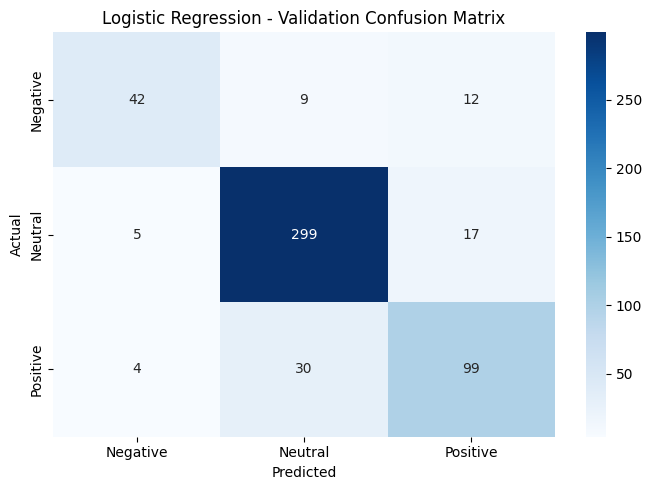

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_val, lr_val_preds)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### 3.2 Baseline 2: BiLSTM + Attention

**Preprocessing.** Sentences are tokenized with a Keras tokenizer fit on the training set (vocabulary limited to 12,000 words; unseen words map to an `<OOV>` token) and padded or truncated to 55 tokens.

In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 12000
MAX_LENGTH = 55

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

VOCAB_SIZE = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", VOCAB_SIZE)
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)

Vocabulary size: 6704
Training shape: (2413, 55)
Validation shape: (517, 55)
Testing shape: (518, 55)


**Attention layer.** A custom layer that scores each time step, applies a softmax (ignoring padding positions through the mask), and returns a weighted sum of the BiLSTM outputs. This lets the model focus on the most informative words in a sentence.

In [13]:
import tensorflow as tf
from tensorflow.keras.layers import Layer, Dense
import keras

@keras.saving.register_keras_serializable()
class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True
        self.attention_dense = Dense(1)

    def call(self, inputs, mask=None):
        scores = self.attention_dense(inputs)
        scores = tf.squeeze(scores, axis=-1)

        if mask is not None:
            scores = tf.where(mask, scores, tf.cast(-1e9, scores.dtype))

        weights = tf.nn.softmax(scores, axis=1)
        context = tf.reduce_sum(
            inputs * tf.expand_dims(weights, axis=-1),
            axis=1
        )

        return context

    def compute_mask(self, inputs, mask=None):
        return None

**Architecture.** Embedding (128 dimensions, masked) → Bidirectional LSTM (64 units) → Attention → Dropout (0.4) → Dense softmax over 3 classes. About 957,000 trainable parameters, trained from scratch.

In [14]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dropout,
    Dense
)

inputs = Input(shape=(MAX_LENGTH,))

embedding = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=128,
    mask_zero=True
)(inputs)

bilstm = Bidirectional(
    LSTM(64, return_sequences=True, dropout=0.2)
)(embedding)

attention = AttentionLayer()(bilstm)

dropout = Dropout(0.4)(attention)

outputs = Dense(3, activation="softmax")(dropout)

bilstm_model = Model(inputs, outputs)

bilstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 55)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 55, 128)   │    858,112 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 55)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 55, 128)   │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_layer     │ (None, 128)       │        129 │ bidirectional[0]… │
│ (AttentionLayer)    │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ attention_layer[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        387 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 957,444 (3.65 MB)

 Trainable params: 957,444 (3.65 MB)

 Non-trainable params: 0 (0.00 B)

**Training.** Adam optimizer (learning rate 0.001), batch size 32, up to 20 epochs, class-weighted loss. Early stopping on validation loss (patience 4, restoring the best weights) and learning-rate reduction on plateau prevent over-training. The training curves below show the model fitting the training data much faster than it improves on validation data, a sign of overfitting on a small dataset.

In [15]:
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = bilstm_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.6366 - loss: 0.9639 - val_accuracy: 0.7253 - val_loss: 0.6878 - learning_rate: 0.0010
Epoch 2/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.8309 - loss: 0.5641 - val_accuracy: 0.8046 - val_loss: 0.5345 - learning_rate: 0.0010
Epoch 3/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9474 - loss: 0.2257 - val_accuracy: 0.8124 - val_loss: 0.5232 - learning_rate: 0.0010
Epoch 4/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9718 - loss: 0.1081 - val_accuracy: 0.8046 - val_loss: 0.5719 - learning_rate: 0.0010
Epoch 5/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9917 - loss: 0.0448
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9921 - loss: 0.0441 - val_accuracy: 0.8182 - val_loss: 0.6045 - learning_rate: 0.0010
Epoch 6/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9946 - loss: 0.0265 - val_acc

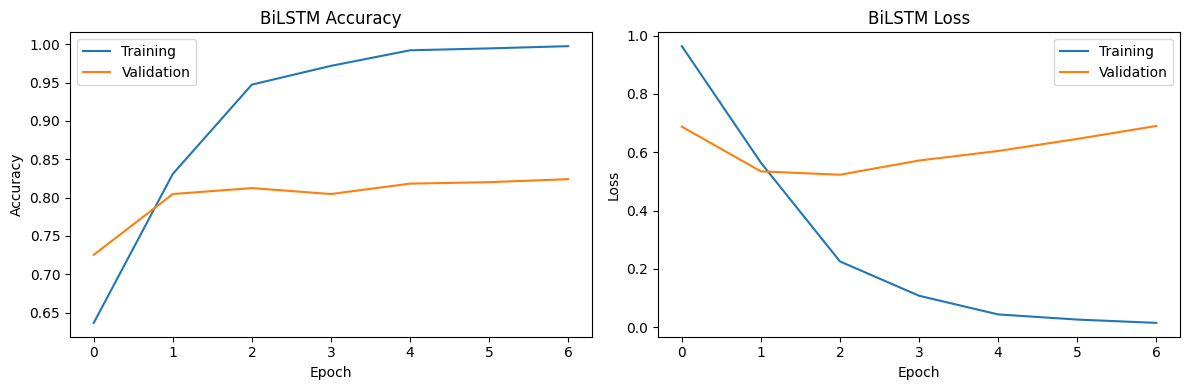

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("BiLSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("BiLSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

**Validation results for the BiLSTM.**

In [17]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

bilstm_val_probs = bilstm_model.predict(X_val_pad, verbose=0)
bilstm_val_preds = np.argmax(bilstm_val_probs, axis=1)

bilstm_val_accuracy = accuracy_score(y_val, bilstm_val_preds)
bilstm_val_macro_f1 = f1_score(y_val, bilstm_val_preds, average="macro")

print("BiLSTM VALIDATION RESULTS")
print("Accuracy:", round(bilstm_val_accuracy, 4))
print("Macro F1:", round(bilstm_val_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    bilstm_val_preds,
    target_names=["Negative", "Neutral", "Positive"]
))

BiLSTM VALIDATION RESULTS
Accuracy: 0.8124
Macro F1: 0.764

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.70      0.70        63
     Neutral       0.89      0.87      0.88       321
    Positive       0.69      0.73      0.71       133

    accuracy                           0.81       517
   macro avg       0.76      0.77      0.76       517
weighted avg       0.81      0.81      0.81       517



### 3.3 Validation Comparison of the Baselines

A side-by-side view of the two baselines on the validation set. Test-set results are reported only later, in Section 5.

In [18]:
comparison = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "BiLSTM + Attention"],
    "Validation Accuracy": [lr_val_accuracy, bilstm_val_accuracy],
    "Validation Macro F1": [lr_val_macro_f1, bilstm_val_macro_f1]
})

display(comparison)

,Model,Validation Accuracy,Validation Macro F1
0,TF-IDF + Logistic Regression,0.851064,0.800966
1,BiLSTM + Attention,0.812379,0.763994


## 4. Main Model: BERT

Installs the Hugging Face libraries used for the transformer models.

In [19]:
!pip -q install transformers accelerate

## Main Model: BERT (`bert-base-uncased`)

The primary transformer comparison uses a general-purpose BERT model fine-tuned only on our training split. ProsusAI/FinBERT is kept in the appendix at the end of this notebook because it was already fine-tuned on Financial PhraseBank.

In [20]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


### 4.1 Loading the Pretrained Model

Loads `bert-base-uncased` with a new, randomly initialized 3-class classification head. The loading report listing the classifier weights as *MISSING* is expected: that head is trained from scratch during fine-tuning. The `id2label` mapping matches the dataset's label scheme (0 negative, 1 neutral, 2 positive).

In [21]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "google-bert/bert-base-uncased"

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

label2id = {v: k for k, v in id2label.items()}

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

bert_model.to(device)

print("BERT loaded successfully!")
print("Device:", device)
print("Labels:", bert_model.config.id2label)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT loaded successfully!
Device: cuda
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


### 4.2 Data Preparation

Wraps the tokenized splits in PyTorch datasets (maximum length 128 tokens) and creates data loaders. Training data is shuffled; validation and test data are not.

In [22]:
from torch.utils.data import Dataset, DataLoader

class BERTSentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.encodings = tokenizer(
            texts.tolist(),
            truncation=True,
            padding="max_length",
            max_length=max_length,
            return_tensors="pt"
        )
        self.labels = torch.tensor(labels.to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx]
        }

bert_train_dataset = BERTSentimentDataset(X_train, y_train, bert_tokenizer)
bert_val_dataset = BERTSentimentDataset(X_val, y_val, bert_tokenizer)
bert_test_dataset = BERTSentimentDataset(X_test, y_test, bert_tokenizer)

bert_train_loader = DataLoader(bert_train_dataset, batch_size=16, shuffle=True)
bert_val_loader = DataLoader(bert_val_dataset, batch_size=32, shuffle=False)
bert_test_loader = DataLoader(bert_test_dataset, batch_size=32, shuffle=False)

print("Training batches:", len(bert_train_loader))
print("Validation batches:", len(bert_val_loader))
print("Testing batches:", len(bert_test_loader))

Training batches: 151
Validation batches: 17
Testing batches: 17


### 4.3 Optimizer and Schedule

AdamW (learning rate 2e-5, weight decay 0.01) with a linear learning-rate schedule and a 10% warmup, over 4 epochs.

In [23]:
from torch.optim import AdamW

bert_optimizer = AdamW(
    bert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("BERT optimizer configured.")

BERT optimizer configured.


In [24]:
from transformers import get_linear_schedule_with_warmup

EPOCHS = 4

total_steps = len(bert_train_loader) * EPOCHS
warmup_steps = int(0.1 * total_steps)

bert_scheduler = get_linear_schedule_with_warmup(
    bert_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Scheduler configured.")

Scheduler configured.


### 4.4 Training and Evaluation Functions

One function runs a training epoch; the other evaluates a model on any loader and returns loss, accuracy, and macro F1.

In [25]:
def train_bert_one_epoch(model, loader):
    model.train()
    total_loss = 0

    for batch in loader:
        bert_optimizer.zero_grad()

        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)

        loss = outputs.loss
        loss.backward()

        bert_optimizer.step()
        bert_scheduler.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [26]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate_bert(model, loader):
    model.eval()
    total_loss = 0
    predictions, actuals = [], []

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)

            total_loss += outputs.loss.item()
            preds = outputs.logits.argmax(dim=1)

            predictions.extend(preds.cpu().numpy())
            actuals.extend(batch["labels"].cpu().numpy())

    return (
        total_loss / len(loader),
        accuracy_score(actuals, predictions),
        f1_score(actuals, predictions, average="macro")
    )

### 4.5 Training with Early Stopping

Trains for up to 4 epochs. After each epoch the model is evaluated on the **validation set**, and the checkpoint with the lowest validation loss is saved. Training stops early if validation loss does not improve for 2 consecutive epochs.

In [27]:
best_val_loss = float("inf")
patience = 2
epochs_without_improvement = 0

history_bert = []

print("Early stopping configured.")

Early stopping configured.


In [28]:
import copy

for epoch in range(EPOCHS):
    train_loss = train_bert_one_epoch(bert_model, bert_train_loader)
    val_loss, val_acc, val_f1 = evaluate_bert(
        bert_model, bert_val_loader
    )

    history_bert.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_acc:.4f} | "
        f"Macro F1: {val_f1:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(bert_model.state_dict(), "aletheia_bert_best.pt")
        print("Best model saved.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

Epoch 1/4 | Train Loss: 0.6974 | Val Loss: 0.3476 | Accuracy: 0.8859 | Macro F1: 0.8631
Best model saved.
Epoch 2/4 | Train Loss: 0.2116 | Val Loss: 0.2453 | Accuracy: 0.9246 | Macro F1: 0.9167
Best model saved.
Epoch 3/4 | Train Loss: 0.0860 | Val Loss: 0.2313 | Accuracy: 0.9362 | Macro F1: 0.9264
Best model saved.
Epoch 4/4 | Train Loss: 0.0473 | Val Loss: 0.2486 | Accuracy: 0.9342 | Macro F1: 0.9224


### 4.6 Test Evaluation

Restores the best checkpoint and evaluates it **once** on the held-out test set. The classification report and confusion matrix show per-class behavior.

In [29]:
bert_model.load_state_dict(
    torch.load("aletheia_bert_best.pt", map_location=device)
)

bert_model.eval()

print("Best BERT checkpoint restored.")

Best BERT checkpoint restored.


In [30]:
test_loss, test_accuracy, test_macro_f1 = evaluate_bert(
    bert_model, bert_test_loader
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

Test Loss: 0.2794
Test Accuracy: 0.9266
Test Macro F1: 0.9047


In [31]:
from sklearn.metrics import classification_report

bert_model.eval()
bert_predictions = []
bert_actuals = []

with torch.no_grad():
    for batch in bert_test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = bert_model(**batch)

        bert_predictions.extend(
            outputs.logits.argmax(dim=1).cpu().numpy()
        )
        bert_actuals.extend(batch["labels"].cpu().numpy())

print(classification_report(
    bert_actuals,
    bert_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.90      0.86      0.88        63
     Neutral       0.97      0.95      0.96       322
    Positive       0.85      0.91      0.88       133

    accuracy                           0.93       518
   macro avg       0.91      0.90      0.90       518
weighted avg       0.93      0.93      0.93       518



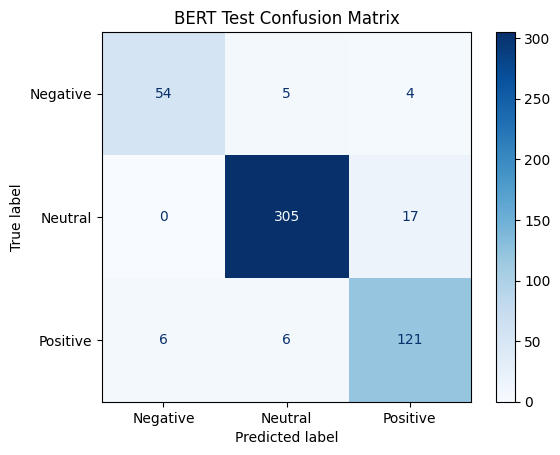

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(bert_actuals, bert_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("BERT Test Confusion Matrix")
plt.show()

## 5. Final Comparison on the Test Set

The two baselines are now evaluated on the same held-out test set, and all three models are compared using accuracy and macro F1.

In [33]:
from sklearn.metrics import accuracy_score, f1_score

lr_test_preds = lr_model.predict(X_test_tfidf)

lr_test_accuracy = accuracy_score(y_test, lr_test_preds)
lr_test_macro_f1 = f1_score(y_test, lr_test_preds, average="macro")

print(f"Test Accuracy: {lr_test_accuracy:.4f}")
print(f"Test Macro F1: {lr_test_macro_f1:.4f}")

Test Accuracy: 0.8475
Test Macro F1: 0.8051


In [34]:
bilstm_test_probs = bilstm_model.predict(X_test_pad, verbose=0)
bilstm_test_preds = np.argmax(bilstm_test_probs, axis=1)

bilstm_test_accuracy = accuracy_score(y_test, bilstm_test_preds)
bilstm_test_macro_f1 = f1_score(
    y_test, bilstm_test_preds, average="macro"
)

print(f"Test Accuracy: {bilstm_test_accuracy:.4f}")
print(f"Test Macro F1: {bilstm_test_macro_f1:.4f}")

Test Accuracy: 0.8301
Test Macro F1: 0.7753


In [35]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "BiLSTM + Attention",
        "BERT"
    ],
    "Test Accuracy": [
        lr_test_accuracy,
        bilstm_test_accuracy,
        test_accuracy
    ],
    "Test Macro F1": [
        lr_test_macro_f1,
        bilstm_test_macro_f1,
        test_macro_f1
    ]
})

display(results.round(4))

,Model,Test Accuracy,Test Macro F1
0,TF-IDF + Logistic Regression,0.8475,0.8051
1,BiLSTM + Attention,0.8301,0.7753
2,BERT,0.9266,0.9047


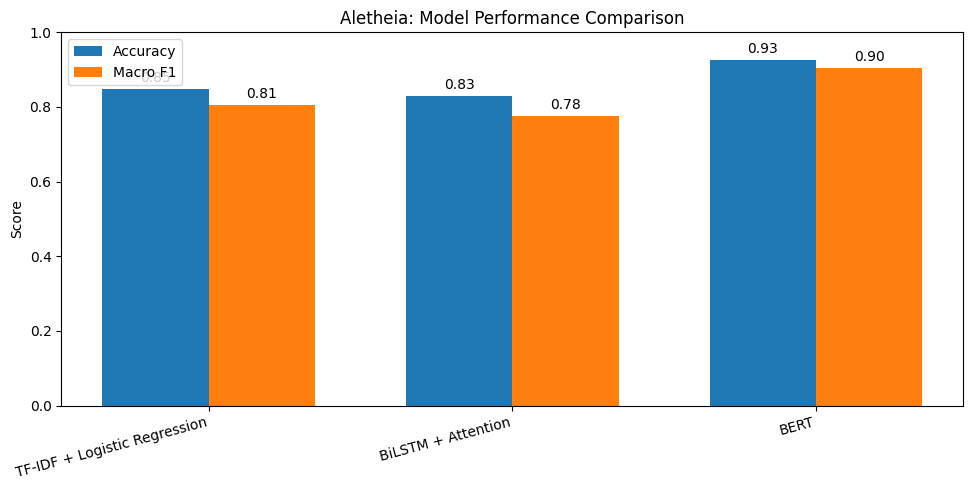

In [36]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(results))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, results["Test Accuracy"], width, label="Accuracy")
plt.bar(x + width/2, results["Test Macro F1"], width, label="Macro F1")

plt.xticks(x, results["Model"], rotation=15, ha="right")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Aletheia: Model Performance Comparison")
plt.legend()
plt.tight_layout()
for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt="%.2f", padding=3)


plt.show()

## 6. Error Analysis

Lists every test sentence BERT misclassified, grouped by error type (actual vs. predicted label), then summarizes the patterns. The written interpretation follows the sentence listing.

In [37]:
error_df = pd.DataFrame({
    "sentence": X_test.reset_index(drop=True),
    "actual": bert_actuals,
    "predicted": bert_predictions
})

error_df = error_df[
    error_df["actual"] != error_df["predicted"]
]

error_df["actual"] = error_df["actual"].map(id2label)
error_df["predicted"] = error_df["predicted"].map(id2label)

print("Total misclassified:", len(error_df))
display(error_df.head(10))

Total misclassified: 38


,sentence,actual,predicted
19,"In a note to clients published , the Dutch bro...",neutral,positive
48,The insurance division turned a EUR120m profit .,neutral,positive
56,Creating interfaces that are more similar to i...,neutral,positive
70,According to Olvi 's Managing Director Lasse A...,positive,neutral
101,"The share sale , to foreign and Finnish invest...",neutral,positive
128,So far the company has awarded more than $ 350...,neutral,positive
130,Net sales for the financial year 2006 are expe...,negative,neutral
139,"( ADP News ) - Nov 28 , 2008 - Finnish power-s...",positive,neutral
144,The second-quarter net sales are expected to b...,neutral,positive
150,Because expenditures must be justified to pass...,neutral,positive


In [38]:
# Display misclassified sentences grouped by error type

for (actual, predicted), group in error_df.groupby(
    ["actual", "predicted"]
):
    print(f"\n{'=' * 70}")
    print(f"Actual: {actual} | Predicted: {predicted}")
    print(f"Number of errors: {len(group)}")
    print("-" * 70)

    for sentence in group["sentence"]:
        print(f"• {sentence}")


Actual: negative | Predicted: neutral
Number of errors: 5
----------------------------------------------------------------------
• Net sales for the financial year 2006 are expected to amount to about EUR20m and the operating result EBIT is expected to be a loss , as announced before .
• The contracts of the employees , 96 of whom are blue-collar workers , will be ended between March and August 2011 .
• The prosecutor is also demanding Outokumpu pay a fine of EUR 800,000 at most .
• The company reported today an operating loss of EUR0 .1 m on net sales of EUR4 .5 m for the first quarter 2008 .
• Many of the commercial vessels had got stuck in the narrow Bay of Bothnia , where the ice is thicker , and around the Aaland islands .

Actual: negative | Predicted: positive
Number of errors: 4
----------------------------------------------------------------------
• Finnish textiles and clothing group Marimekko Oyj posted a net profit of 7.99 mln euro $ 10.4 mln for 2006 , compared to 8.4 mln

### Error Analysis and Misclassification Patterns

In the final run, the BERT model misclassified 38 of 518 test sentences (7.34%). Most errors were between the neutral and positive classes: 17 neutral sentences were predicted as positive and 6 positive sentences were predicted as neutral, together 23 of the 38 errors (about 61%). The remaining errors were spread across positive → negative (6), negative → neutral (5), and negative → positive (4).

Retraining BERT gives slightly different error counts each time (an earlier run produced 40 errors), but neutral vs. positive confusion was the largest error type in both runs, so the pattern is more reliable than the exact counts.

This suggests that distinguishing neutral financial statements from mildly positive ones is the key challenge. Some financial sentences state facts that indirectly imply good performance, which blurs the boundary between neutral and positive.

For example, a statement reporting that an insurance division turned a profit may be read as positive by a model, even though the dataset labels it neutral.

Examples like this point to possible annotation ambiguity in financial sentiment datasets. However, individual misclassifications are not enough to establish that the original labels are wrong.

Overall, the model performs well, but its remaining errors show that subtle differences in financial context and sentiment interpretation are still hard.

In [39]:
error_patterns = error_df.groupby(
    ["actual", "predicted"]
).size().reset_index(name="count")

display(error_patterns.sort_values("count", ascending=False))

,actual,predicted,count
2,neutral,positive,17
4,positive,neutral,6
3,positive,negative,6
0,negative,neutral,5
1,negative,positive,4


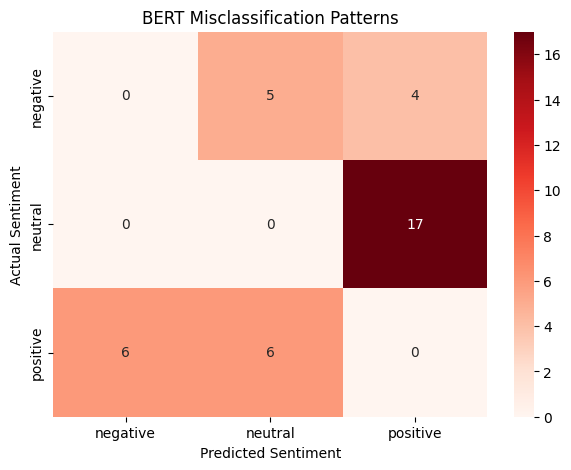

In [40]:
import seaborn as sns

error_matrix = pd.crosstab(
    error_df["actual"],
    error_df["predicted"]
).reindex(
    index=["negative", "neutral", "positive"],
    columns=["negative", "neutral", "positive"],
    fill_value=0
)

plt.figure(figsize=(7, 5))
sns.heatmap(error_matrix, annot=True, fmt="d", cmap="Reds")
plt.title("BERT Misclassification Patterns")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

## 7. Saving Models

Saves the fine-tuned BERT model and tokenizer (used by the Gradio demo), plus the logistic regression pipeline, the BiLSTM, and its tokenizer.

In [41]:
bert_model.save_pretrained("aletheia_bert")
bert_tokenizer.save_pretrained("aletheia_bert")

print("BERT model and tokenizer saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model and tokenizer saved successfully.


In [42]:
import joblib
import pickle

joblib.dump(
    {"model": lr_model, "vectorizer": tfidf},
    "aletheia_logistic_regression.joblib"
)

bilstm_model.save("aletheia_bilstm.keras")

with open("aletheia_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Logistic Regression, BiLSTM and tokenizer saved.")

Logistic Regression, BiLSTM and tokenizer saved.


## 8. Uncertainty Analysis

Bootstrap resampling of the test set (2,000 iterations) to compute 95% confidence intervals for accuracy and macro F1 for all three models. The interpretation follows the results.

In [43]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Predictions from all three models
model_predictions = {
    "TF-IDF + Logistic Regression": lr_test_preds,
    "BiLSTM + Attention": bilstm_test_preds,
    "BERT": bert_predictions
}

def bootstrap_metrics(y_true, y_pred, n_iterations=2000):
    rng = np.random.default_rng(42)

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    accuracies = []
    macro_f1_scores = []

    for _ in range(n_iterations):
        indices = rng.choice(len(y_true), size=len(y_true), replace=True)

        actual = y_true[indices]
        predicted = y_pred[indices]

        accuracies.append(accuracy_score(actual, predicted))
        macro_f1_scores.append(
            f1_score(actual, predicted, average="macro", zero_division=0)
        )

    return {
        "Accuracy CI": np.percentile(accuracies, [2.5, 97.5]),
        "Macro F1 CI": np.percentile(macro_f1_scores, [2.5, 97.5])
    }

# Calculate confidence intervals
for model_name, predictions in model_predictions.items():
    bootstrap_result = bootstrap_metrics(y_test, predictions)

    print(f"\n{model_name}")
    print(
        f"Accuracy 95% CI: "
        f"{bootstrap_result['Accuracy CI'][0]:.4f} - "
        f"{bootstrap_result['Accuracy CI'][1]:.4f}"
    )
    print(
        f"Macro F1 95% CI: "
        f"{bootstrap_result['Macro F1 CI'][0]:.4f} - "
        f"{bootstrap_result['Macro F1 CI'][1]:.4f}"
    )


TF-IDF + Logistic Regression
Accuracy 95% CI: 0.8166 - 0.8784
Macro F1 95% CI: 0.7599 - 0.8458

BiLSTM + Attention
Accuracy 95% CI: 0.7973 - 0.8629
Macro F1 95% CI: 0.7279 - 0.8193

BERT
Accuracy 95% CI: 0.9035 - 0.9479
Macro F1 95% CI: 0.8727 - 0.9343


### Uncertainty Analysis: Bootstrap Confidence Intervals

To assess the uncertainty in model performance, bootstrap resampling was performed on the test set using 2,000 iterations. The 95% confidence intervals were estimated using the 2.5th and 97.5th percentiles of the resulting metric distributions.

The results show that:

- **TF-IDF + Logistic Regression:** Accuracy ranged from 81.66% to 87.84%, while macro F1 ranged from 75.99% to 84.58%.
- **BiLSTM + Attention:** Accuracy ranged from 79.73% to 86.29%, while macro F1 ranged from 72.79% to 81.93%.
- **BERT:** Accuracy ranged from 90.35% to 94.79%, while macro F1 ranged from 87.27% to 93.43%.

BERT achieved the highest point estimates, and its confidence intervals do not overlap with those of either baseline for accuracy or macro F1. This provides evidence that BERT performs better on this test set.

However, bootstrap confidence intervals quantify uncertainty from test-set sampling, not variability across different training runs. Section 10 addresses that separately by retraining BERT with three random seeds. The results should also not be read as a guarantee of performance on unseen financial datasets.

In [44]:
results.to_csv("aletheia_model_comparison.csv", index=False)

print("Model comparison saved successfully.")

Model comparison saved successfully.


## 9. External Generalization

Tests whether the fine-tuned BERT model holds up on a **different kind of financial text**: the *Twitter Financial News Sentiment* dataset (short, informal tweets about stocks, versus formal news sentences in Financial PhraseBank). No further training is done on this data.

Its labels are mapped to this project's scheme: Bearish → negative, Bullish → positive, Neutral → neutral. The mapping is printed and spot-checked before any evaluation.

In [45]:
from datasets import load_dataset

external_dataset = load_dataset(
    "zeroshot/twitter-financial-news-sentiment"
)

external_test = external_dataset["validation"].to_pandas()

print("External dataset shape:", external_test.shape)
print("\nColumns:", external_test.columns.tolist())
print("\nLabel distribution:")
print(external_test["label"].value_counts().sort_index())

display(external_test.head())

README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

sent_train.csv:   0%|          | 0.00/859k [00:00<?, ?B/s]

sent_valid.csv:   0%|          | 0.00/217k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

External dataset shape: (2388, 2)

Columns: ['text', 'label']

Label distribution:
label
0     347
1     475
2    1566
Name: count, dtype: int64


,text,label
0,$ALLY - Ally Financial pulls outlook https://t...,0
1,"$DELL $HPE - Dell, HPE targets trimmed on comp...",0
2,$PRTY - Moody's turns negative on Party City h...,0
3,$SAN: Deutsche Bank cuts to Hold,0
4,$SITC: Compass Point cuts to Sell,0


In [46]:
# Map external dataset labels to Aletheia's label scheme

external_label_map = {
    0: 0,  # Bearish -> Negative
    1: 2,  # Bullish -> Positive
    2: 1   # Neutral -> Neutral
}

external_test["mapped_label"] = (
    external_test["label"].map(external_label_map)
)

print("Mapped label distribution:")
print(external_test["mapped_label"].value_counts().sort_index())

print("\nLabel mapping verified:")
print(external_test[["text", "label", "mapped_label"]].head(10))

Mapped label distribution:
mapped_label
0     347
1    1566
2     475
Name: count, dtype: int64

Label mapping verified:
                                                text  label  mapped_label
0  $ALLY - Ally Financial pulls outlook https://t...      0             0
1  $DELL $HPE - Dell, HPE targets trimmed on comp...      0             0
2  $PRTY - Moody's turns negative on Party City h...      0             0
3                   $SAN: Deutsche Bank cuts to Hold      0             0
4                  $SITC: Compass Point cuts to Sell      0             0
5  $TAP - Barclays cools on Molson Coors https://...      0             0
6                $TAP: Barclays cuts to Equal Weight      0             0
7  Analysts Eviscerate Musk's Cybertruck: "0% Of ...      0             0
8  Barclays assigns only a 20% chance that studie...      0             0
9  BTIG points to breakfast pressure for Dunkin' ...      0             0


In [47]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load the already fine-tuned model
external_tokenizer = AutoTokenizer.from_pretrained("./aletheia_bert")

external_model = AutoModelForSequenceClassification.from_pretrained(
    "./aletheia_bert"
)

external_model.to(device)
external_model.eval()

print("Aletheia BERT model loaded successfully!")
print(external_model.config.id2label)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Aletheia BERT model loaded successfully!
{0: 'negative', 1: 'neutral', 2: 'positive'}


In [48]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

texts = external_test["text"].tolist()
external_predictions = []

for i in range(0, len(texts), 32):
    batch = external_tokenizer(
        texts[i:i+32],
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = external_model(**batch)

    external_predictions.extend(
        outputs.logits.argmax(dim=1).cpu().numpy()
    )

external_actuals = external_test["mapped_label"].to_numpy()

print("Accuracy:", accuracy_score(external_actuals, external_predictions))
print("Macro F1:", f1_score(external_actuals, external_predictions, average="macro"))

print(classification_report(
    external_actuals,
    external_predictions,
    target_names=["Negative", "Neutral", "Positive"]
))

Accuracy: 0.748324958123953
Macro F1: 0.6629871332327198
              precision    recall  f1-score   support

    Negative       0.64      0.56      0.60       347
     Neutral       0.79      0.86      0.83      1566
    Positive       0.63      0.51      0.56       475

    accuracy                           0.75      2388
   macro avg       0.69      0.64      0.66      2388
weighted avg       0.74      0.75      0.74      2388



### External Generalization Evaluation

To assess generalization beyond the training domain, the fine-tuned BERT model was evaluated on the validation split of the Twitter Financial News Sentiment dataset, containing 2,388 samples.

The model achieved 74.83% accuracy and 66.30% macro F1, compared with 92.66% accuracy and 90.47% macro F1 on the Financial PhraseBank test set. This is a decrease of 17.83 percentage points in accuracy and 24.17 percentage points in macro F1.

The external evaluation reveals a clear domain generalization gap. The model performs relatively well on neutral statements (F1 0.83), but its F1 scores for negative and positive sentiment are considerably lower (0.60 and 0.56 respectively).

Possible contributing factors include differences in writing style (short, informal tweets versus formal news sentences), vocabulary, financial context, and class distribution between the two datasets.

These findings suggest that strong in-domain performance does not necessarily translate into equally strong performance on different financial text sources. The external dataset was used exclusively for evaluation, without additional fine-tuning. The next section compares this drop against the two baselines.

### External Evaluation: All Three Models

The Twitter Financial News dataset is also used to test the two baselines, so the generalization gap can be compared across models rather than attributed to BERT alone.

In [49]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import accuracy_score, f1_score

ext_texts = external_test["text"].tolist()

# TF-IDF + Logistic Regression
lr_ext_preds = lr_model.predict(tfidf.transform(ext_texts))

# BiLSTM + Attention
ext_seq = tokenizer.texts_to_sequences(ext_texts)
ext_pad = pad_sequences(ext_seq, maxlen=MAX_LENGTH, padding="post", truncating="post")
bilstm_ext_preds = np.argmax(bilstm_model.predict(ext_pad, verbose=0), axis=1)

# BERT predictions were computed in the previous section
ext_results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "BiLSTM + Attention", "BERT"],
    "In-domain Accuracy": [lr_test_accuracy, bilstm_test_accuracy, test_accuracy],
    "External Accuracy": [
        accuracy_score(external_actuals, lr_ext_preds),
        accuracy_score(external_actuals, bilstm_ext_preds),
        accuracy_score(external_actuals, external_predictions),
    ],
    "In-domain Macro F1": [lr_test_macro_f1, bilstm_test_macro_f1, test_macro_f1],
    "External Macro F1": [
        f1_score(external_actuals, lr_ext_preds, average="macro"),
        f1_score(external_actuals, bilstm_ext_preds, average="macro"),
        f1_score(external_actuals, external_predictions, average="macro"),
    ],
})

ext_results["Accuracy Drop"] = ext_results["In-domain Accuracy"] - ext_results["External Accuracy"]
ext_results["Macro F1 Drop"] = ext_results["In-domain Macro F1"] - ext_results["External Macro F1"]

display(ext_results.round(4))
ext_results.to_csv("aletheia_external_comparison.csv", index=False)

,Model,In-domain Accuracy,External Accuracy,In-domain Macro F1,External Macro F1,Accuracy Drop,Macro F1 Drop
0,TF-IDF + Logistic Regression,0.8475,0.6524,0.8051,0.4349,0.1951,0.3702
1,BiLSTM + Attention,0.8301,0.6650,0.7753,0.4614,0.1651,0.3140
2,BERT,0.9266,0.7483,0.9047,0.6630,0.1783,0.2417


**Interpretation.** All three models lose accuracy on the Twitter data, so the gap is mostly **domain shift**, not something specific to BERT. Accuracy fell by 19.5 points for logistic regression, 16.5 for the BiLSTM, and 17.8 for BERT, which are similar drops.

The difference shows up in **macro F1**. BERT keeps 0.663, while logistic regression falls to 0.435 and the BiLSTM to 0.461 (drops of 24.2, 37.0, and 31.4 points respectively). The baselines lose far more of their ability to recognize the negative and positive classes.

An important caveat is that the external set is about 65.6% neutral (1,566 of 2,388 tweets), so a model that always predicted "neutral" would score roughly 65.6% accuracy. Logistic regression (65.2%) and the BiLSTM (66.5%) are essentially at that level, so their accuracy hides the fact that they barely beat blind guessing. BERT's 74.8% is about 9 points above that baseline.

**Takeaway:** pretraining on large text helps BERT transfer to informal financial text far better than models trained from scratch on a small dataset, but even BERT is not reliable on tweets without further adaptation.

## 10. Training Variability

### Training Variability: BERT Across Random Seeds

Bootstrap confidence intervals capture test-set sampling uncertainty only. To estimate variability from training randomness, BERT is retrained from scratch with three seeds using the same split, hyperparameters, and checkpoint selection (best validation loss). Results are reported on the same held-out test set.

In [50]:
import gc
import pandas as pd
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def run_bert_seed(seed, epochs=4, patience=2):
    set_all_seeds(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        "google-bert/bert-base-uncased",
        num_labels=3,
        id2label=id2label,
        label2id=label2id
    ).to(device)

    generator = torch.Generator()
    generator.manual_seed(seed)
    train_loader = DataLoader(
        bert_train_dataset, batch_size=16, shuffle=True, generator=generator
    )

    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, int(0.1 * total_steps), total_steps
    )

    best_val_loss = float("inf")
    best_state = None
    bad_epochs = 0

    for epoch in range(epochs):
        model.train()
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            loss = model(**batch).loss
            loss.backward()
            optimizer.step()
            scheduler.step()

        val_loss, _, _ = evaluate_bert(model, bert_val_loader)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break

    model.load_state_dict(best_state)
    _, test_acc, test_f1 = evaluate_bert(model, bert_test_loader)

    del model, optimizer, scheduler, best_state
    gc.collect()
    torch.cuda.empty_cache()

    return test_acc, test_f1

seed_rows = []
for seed in [42, 7, 123]:
    acc, f1 = run_bert_seed(seed)
    seed_rows.append({"Seed": seed, "Test Accuracy": acc, "Test Macro F1": f1})
    print(f"Seed {seed}: Accuracy={acc:.4f} | Macro F1={f1:.4f}")

seed_df = pd.DataFrame(seed_rows)
summary = pd.DataFrame({
    "Metric": ["Test Accuracy", "Test Macro F1"],
    "Mean": [seed_df["Test Accuracy"].mean(), seed_df["Test Macro F1"].mean()],
    "Std": [seed_df["Test Accuracy"].std(), seed_df["Test Macro F1"].std()],
})

display(seed_df.round(4))
display(summary.round(4))
seed_df.to_csv("aletheia_bert_seed_results.csv", index=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Seed 42: Accuracy=0.9305 | Macro F1=0.9098


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Seed 7: Accuracy=0.9344 | Macro F1=0.9213


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Seed 123: Accuracy=0.9247 | Macro F1=0.9069


,Seed,Test Accuracy,Test Macro F1
0,42,0.9305,0.9098
1,7,0.9344,0.9213
2,123,0.9247,0.9069


,Metric,Mean,Std
0,Test Accuracy,0.9299,0.0049
1,Test Macro F1,0.9127,0.0076


**Interpretation.** Across three seeds, BERT's test accuracy ranged from 92.47% to 93.44% (mean 92.99%, std 0.49 points) and its macro F1 from 0.9069 to 0.9213 (mean 0.9127, std 0.0076).

**Every seed beat both baselines** (best baseline: logistic regression at 84.75% accuracy and 0.8051 macro F1) by more than 7 points of accuracy, so BERT's advantage is not the result of one lucky run. Run-to-run variation (under 1 point) is much smaller than the gap between models.

GPU training is not fully deterministic, so the single-run result in Sections 4 and 5 (92.66%) differs slightly from these runs. The **mean ± std over seeds is the more reliable headline number** to quote.

## Conclusions

**Main findings**
- **BERT is the strongest model** on the Financial PhraseBank test set: 92.66% accuracy and 0.9047 macro F1 in the main run, and 92.99% ± 0.49 accuracy and 0.9127 ± 0.0076 macro F1 across three seeds. The best baseline (logistic regression) reached 84.75% and 0.8051. BERT's bootstrap confidence intervals do not overlap with either baseline's (Section 8), and every seed beat both baselines (Section 10).
- **TF-IDF + Logistic Regression beat the BiLSTM.** With only about 2,400 training sentences, the BiLSTM overfits (training accuracy far above validation accuracy), while the simpler linear model generalizes better. This is a common result on small datasets.
- **Most BERT errors are between neutral and positive** (23 of 38 test errors in the final run). Some of these sentences are genuinely ambiguous, for example factual statements about profit that the dataset labels as neutral, which suggests part of the remaining error comes from label ambiguity and not only model weakness.
- **All models drop on tweets, but BERT holds up best.** On the external Twitter dataset, accuracy fell by about 17 to 20 points for all three models. BERT kept a macro F1 of 0.663, versus 0.435 (logistic regression) and 0.461 (BiLSTM). The baselines' external accuracy (about 65%) is close to the 65.6% you would get by always predicting neutral, so they mostly fail on negative and positive tweets (Section 9).

**Limitations**
- Small dataset (about 3,400 sentences), with possible label noise from annotator disagreement.
- Formal news-style English only; informal text performs much worse, even for BERT.
- Bootstrap intervals measure test-set sampling uncertainty only; Section 10 covers training randomness with three seeds, which is still a small number.
- Retraining gives slightly different numbers each time because GPU training is not fully deterministic, so exact figures vary a little between runs.
- ProsusAI/FinBERT could not be fairly compared because it was already fine-tuned on this dataset (see the Appendix).
- Not intended for trading or investment decisions.

---
## Appendix: Contaminated Baseline (ProsusAI/FinBERT)

**This section is not part of the primary model comparison.** ProsusAI/FinBERT was previously fine-tuned on Financial PhraseBank, so its validation scores cannot be treated as independent evidence. The cells below are kept for reference only.

### A.1 Loading FinBERT

Loads `ProsusAI/finbert` and prints its label order (`0 positive, 1 negative, 2 neutral`), which differs from this project's order. The label map defined in the next section translates between the two.

In [51]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "ProsusAI/finbert"

finbert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

finbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    ignore_mismatched_sizes=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
finbert_model.to(device)

print("FinBERT loaded successfully!")
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Label configuration:", finbert_model.config.id2label)

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

FinBERT loaded successfully!
Device: cuda
GPU: Tesla T4
Label configuration: {0: 'positive', 1: 'negative', 2: 'neutral'}


### A.2 Data and Label Mapping

Maps this project's labels (0 negative, 1 neutral, 2 positive) to FinBERT's (0 positive, 1 negative, 2 neutral), and builds the data loaders with FinBERT's own tokenizer.

In [52]:
from torch.utils.data import Dataset, DataLoader

finbert_label_map = {
    0: 1,
    1: 2,
    2: 0
}

class FinancialSentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts.tolist()
        self.labels = [finbert_label_map[int(label)] for label in labels]
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = FinancialSentimentDataset(X_train, y_train, finbert_tokenizer)
val_dataset = FinancialSentimentDataset(X_val, y_val, finbert_tokenizer)
test_dataset = FinancialSentimentDataset(X_test, y_test, finbert_tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 151
Validation batches: 17
Testing batches: 17


In [53]:
from transformers import get_linear_schedule_with_warmup

EPOCHS = 4

optimizer = AdamW(
    finbert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Optimizer and scheduler configured.")

Optimizer and scheduler configured.


In [54]:
import copy

EPOCHS = 4
best_val_loss = float("inf")
patience = 2
patience_counter = 0

finbert_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": []
}

best_model_state = None

print("FinBERT training configuration ready.")
print("Epochs:", EPOCHS)
print("Early stopping patience:", patience)
print("Device:", device)

FinBERT training configuration ready.
Epochs: 4
Early stopping patience: 2
Device: cuda


### A.3 Training Helpers

Functions for one training epoch (with gradient clipping) and for evaluation.

In [55]:
def train_one_epoch(model, loader, optimizer, scheduler, device):
    model.train()
    total_loss = 0

    for batch in loader:
        optimizer.zero_grad(set_to_none=True)

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [56]:
def evaluate_model(model, loader, device):
    model.eval()

    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()

            predictions = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average="macro")

    return avg_loss, accuracy, macro_f1

### A.4 Epoch-by-Epoch Training

Run one epoch at a time to watch validation behavior. Validation accuracy is already about 95% after the first epoch, well above what the baselines reach (about 85% at best), which is consistent with the model having seen this data before.

In [57]:
train_loss = train_one_epoch(
    finbert_model,
    train_loader,
    optimizer,
    scheduler,
    device
)

print("Epoch 1 training completed.")
print("Training loss:", round(train_loss, 4))

Epoch 1 training completed.
Training loss: 0.1615


In [58]:
val_loss, val_accuracy, val_macro_f1 = evaluate_model(
    finbert_model,
    val_loader,
    device
)

print("EPOCH 1 VALIDATION")
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_macro_f1, 4))

EPOCH 1 VALIDATION
Validation Loss: 0.2143
Validation Accuracy: 0.9478
Validation Macro F1: 0.9306


In [59]:
best_val_loss = val_loss
best_val_f1 = val_macro_f1
best_epoch = 1
best_model_state = copy.deepcopy(finbert_model.state_dict())
patience_counter = 0

finbert_history["train_loss"].append(train_loss)
finbert_history["val_loss"].append(val_loss)
finbert_history["val_accuracy"].append(val_accuracy)
finbert_history["val_macro_f1"].append(val_macro_f1)

print("Epoch 1 recorded. Best checkpoint saved.")

Epoch 1 recorded. Best checkpoint saved.


In [60]:
train_loss = train_one_epoch(
    finbert_model,
    train_loader,
    optimizer,
    scheduler,
    device
)

print("Epoch 2 training completed.")
print("Training loss:", round(train_loss, 4))


Epoch 2 training completed.
Training loss: 0.0705


In [61]:
val_loss, val_accuracy, val_macro_f1 = evaluate_model(
    finbert_model,
    val_loader,
    device
)

print("EPOCH 2 VALIDATION")
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_macro_f1, 4))

EPOCH 2 VALIDATION
Validation Loss: 0.2133
Validation Accuracy: 0.9574
Validation Macro F1: 0.9492


In [62]:
EPOCH_NUMBER = 2

finbert_history["train_loss"].append(train_loss)
finbert_history["val_loss"].append(val_loss)
finbert_history["val_accuracy"].append(val_accuracy)
finbert_history["val_macro_f1"].append(val_macro_f1)

if val_loss < best_val_loss:
    best_val_loss = val_loss
    best_val_f1 = val_macro_f1
    best_epoch = EPOCH_NUMBER
    best_model_state = copy.deepcopy(finbert_model.state_dict())
    patience_counter = 0
    print(f"Epoch {EPOCH_NUMBER} recorded: new best checkpoint saved.")
else:
    patience_counter += 1
    print(f"Epoch {EPOCH_NUMBER} recorded: no improvement in validation loss.")

print("Best epoch so far:", best_epoch)
print("Early stopping counter:", patience_counter, "of", patience)
if patience_counter >= patience:
    print("Early stopping would trigger here.")

Epoch 2 recorded: new best checkpoint saved.
Best epoch so far: 2
Early stopping counter: 0 of 2


In [63]:
train_loss = train_one_epoch(
    finbert_model,
    train_loader,
    optimizer,
    scheduler,
    device
)

print("Epoch 3 training loss:", round(train_loss, 4))

Epoch 3 training loss: 0.0243


In [64]:
val_loss, val_accuracy, val_macro_f1 = evaluate_model(
    finbert_model,
    val_loader,
    device
)

print("EPOCH 3 VALIDATION")
print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_macro_f1, 4))

EPOCH 3 VALIDATION
Validation Loss: 0.2251
Validation Accuracy: 0.9536
Validation Macro F1: 0.9358


In [65]:
EPOCH_NUMBER = 3

finbert_history["train_loss"].append(train_loss)
finbert_history["val_loss"].append(val_loss)
finbert_history["val_accuracy"].append(val_accuracy)
finbert_history["val_macro_f1"].append(val_macro_f1)

if val_loss < best_val_loss:
    best_val_loss = val_loss
    best_val_f1 = val_macro_f1
    best_epoch = EPOCH_NUMBER
    best_model_state = copy.deepcopy(finbert_model.state_dict())
    patience_counter = 0
    print(f"Epoch {EPOCH_NUMBER} recorded: new best checkpoint saved.")
else:
    patience_counter += 1
    print(f"Epoch {EPOCH_NUMBER} recorded: no improvement in validation loss.")

print("Best epoch so far:", best_epoch)
print("Early stopping counter:", patience_counter, "of", patience)
if patience_counter >= patience:
    print("Early stopping would trigger here.")

Epoch 3 recorded: no improvement in validation loss.
Best epoch so far: 2
Early stopping counter: 1 of 2


#### Appendix Summary: Why FinBERT Is Excluded

ProsusAI/FinBERT achieved 94.78% validation accuracy and 93.06% macro F1 after its first epoch, rising to 95.74% and 94.92% after the second epoch.

**Data contamination:** The model was previously fine-tuned on Financial PhraseBank, the same dataset used in this project. Consequently, its validation results cannot be considered an independent evaluation or fairly compared with models trained only on our training split.

Validation loss barely moved across epochs (0.2143, 0.2133, 0.2251) while validation accuracy stayed around 95 to 96%. A flat loss like this does not establish overfitting. The primary methodological concern is prior exposure to the evaluation dataset during supervised fine-tuning.

**Decision:** This experiment is retained for reference only and excluded from the primary model comparison. A general-purpose BERT model (`google-bert/bert-base-uncased`) was fine-tuned separately using our training split for a fairer comparison.